# Fase 1: Auditoría Integral, Limpieza, Reconciliación Forense y EDA
## Proyecto: Inteligencia de Negocios y Aprendizaje Automático para el Pronóstico de IRAs en Menores de 5 Años en Puno (2000–2025)

**Dataset Oficial:** `datos_abiertos_vigilancia_iras_2000_2025 PUNO.csv` (MINSA / CDC Perú – NotiSP)  
**Ámbito Territorial:** Región Puno (13 Provincias, 110 Distritos oficiales INEI)  
**Rol Técnico:** Científico de Datos Senior en Epidemiología, Calidad de Datos y BI  

---

### Objetivos Específicos de la Fase 1:
1. **Reconciliación y Control de Calidad:** Confirmación empírica del total real de 2,297,378 episodios; clarificación de la discrepancia documental de 732 del borrador v1.
2. **Auditoría de Codificación:** Diagnóstico de UTF-8 con BOM (`utf-8-sig`) y restauración determinística de distritos con caracter `U+FFFD`.
3. **Auditoría de Semanas MINSA:** Separación de semanas teóricas (17,641), observadas (17,488) y ausencias de registro (153).
4. **Preservación de Faltantes sin Datos Inventados:** Conservación estricta de `NaN` en ausencias de registro y bandera `es_evaluable`.
5. **Aditividad y Notificación Múltiple:** Evaluación de duplicados espacio-temporales y rol de `sub_reg_nt`.
6. **Epistemología de Ceros:** Diferenciación entre reporte de cero y ausencia de notificación.
7. **Construcción de Paneles para Modelado:** Paneles provincial y regional curados para la Fase 2.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

raw_path = os.path.join("..", "data", "raw", "datos_abiertos_vigilancia_iras_2000_2025 PUNO.csv")
if not os.path.exists(raw_path):
    raw_path = os.path.join("data", "raw", "datos_abiertos_vigilancia_iras_2000_2025 PUNO.csv")

df = pd.read_csv(raw_path, encoding="utf-8-sig", dtype={"ubigeo": str})
print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas")


Dataset cargado: 126,118 filas x 14 columnas


### 1. Reconciliación del Total de Episodios de IRA no Neumonía
Verificación directa del total regional frente a la suma agregada de las 13 provincias.

In [2]:
total_directo = int(df["ira_no_neumonia"].sum())
prov_sums = df.groupby("provincia")["ira_no_neumonia"].sum()
total_provincial = int(prov_sums.sum())

print(f"Total directo en CSV:            {total_directo:,}")
print(f"Suma agregada de 13 provincias: {total_provincial:,}")
print(f"Diferencia:                     {total_directo - total_provincial}")

assert total_directo == total_provincial, "Discrepancia detectada en agregación provincial"
print(">>> Reconciliación confirmada: el total inalterado del dataset es 2,297,378 episodios.")


Total directo en CSV:            2,297,378
Suma agregada de 13 provincias: 2,297,378
Diferencia:                     0
>>> Reconciliación confirmada: el total inalterado del dataset es 2,297,378 episodios.


### 2. Auditoría del Calendario Epidemiológico MINSA y Preservación de NaN
Cálculo de semanas teóricas esperadas (1,357 regionales $	imes$ 13 provincias = 17,641) vs observadas (17,488) vs faltantes con `NaN` (153).

In [3]:
anios_semana_53 = {2003, 2008, 2014, 2020, 2025}
semanas_esperadas_ano = {ano: 53 if ano in anios_semana_53 else 52 for ano in range(2000, 2026)}
total_semanas_esperadas = sum(semanas_esperadas_ano.values())
print(f"Total semanas oficiales esperadas en 26 años: {total_semanas_esperadas}")

panel_prov_path = os.path.join("..", "data", "processed", "panel_semanal_provincial_puno.parquet")
if not os.path.exists(panel_prov_path):
    panel_prov_path = os.path.join("data", "processed", "panel_semanal_provincial_puno.parquet")

df_panel_prov = pd.read_parquet(panel_prov_path)
print(f"Filas en panel provincial: {len(df_panel_prov):,}")
print(f"Valores NaN en semanas sin registro: {df_panel_prov['ira_no_neumonia'].isna().sum()}")
print(f"Semanas evaluables para métricas (es_evaluable == True): {df_panel_prov['es_evaluable'].sum():,}")


Total semanas oficiales esperadas en 26 años: 1357
Filas en panel provincial: 17,641
Valores NaN en semanas sin registro: 153
Semanas evaluables para métricas (es_evaluable == True): 17,488


### 3. Análisis de Claves Repetidas y Notificación Múltiple
Evaluación de las 3,935 filas con claves `[ano, semana, ubigeo]` compartidas entre diferentes subregiones notificadoras.

In [4]:
key_cols = ["ano", "semana", "ubigeo"]
key_dups = df[df.duplicated(subset=key_cols, keep=False)]
print(f"Total registros involucrados en claves repetidas: {len(key_dups):,}")
print(f"Total combinaciones únicas de clave: {key_dups.groupby(key_cols).ngroups:,}")
print("\nDistribución por Subregión Notificante (sub_reg_nt) en claves repetidas:")
print(key_dups["sub_reg_nt"].value_counts().head(8))


Total registros involucrados en claves repetidas: 3,935


Total combinaciones únicas de clave: 1,781

Distribución por Subregión Notificante (sub_reg_nt) en claves repetidas:
sub_reg_nt
21    1780
4     1037
50     791
8      162
33      71
7       27
53      19
52      11
Name: count, dtype: int64


### 4. Normalización Geográfica y Corrección de `U+FFFD`
Restauración verificable de `MUÑANI` (210208), `NUÑOA` (210806) y `MAÑAZO` (210109).

In [5]:
corrections = {"210208": "MUÑANI", "210806": "NUÑOA", "210109": "MAÑAZO"}
df_clean = df.copy()
for ubi, name in corrections.items():
    df_clean.loc[df_clean["ubigeo"] == ubi, "distrito"] = name

df_clean["ubigeo"] = df_clean["ubigeo"].astype(str).str.zfill(6)
df_clean["ano_semana"] = df_clean["ano"].astype(str) + "-W" + df_clean["semana"].astype(str).str.zfill(2)

print(f"Caracteres inválidos U+FFFD restantes en distrito: {df_clean['distrito'].str.contains(chr(0xfffd)).sum()}")


Caracteres inválidos U+FFFD restantes en distrito: 0


### 5. Análisis Exploratorio de Datos (EDA)
Curva estacional regional delimitando el período de bajas temperaturas (SE 20–32).

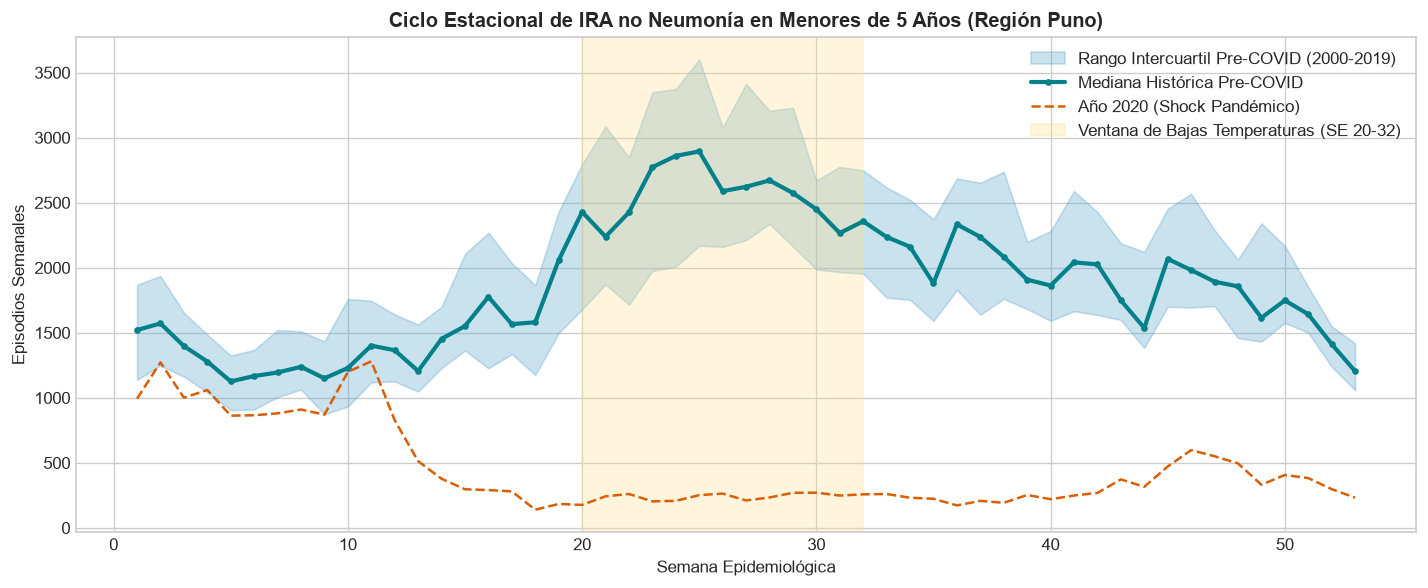

In [6]:
reg_weekly = df_clean.groupby(["ano", "semana"])["ira_no_neumonia"].sum().reset_index()
base = reg_weekly[reg_weekly["ano"] < 2020].groupby("semana")["ira_no_neumonia"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(base.median().index, base.quantile(0.25), base.quantile(0.75), color="#67a9cf", alpha=0.35, label="Rango Intercuartil Pre-COVID (2000-2019)")
ax.plot(base.median().index, base.median(), color="#02818a", linewidth=2.5, marker="o", markersize=3, label="Mediana Histórica Pre-COVID")
ax.plot(reg_weekly[reg_weekly["ano"] == 2020].sort_values("semana")["semana"], reg_weekly[reg_weekly["ano"] == 2020].sort_values("semana")["ira_no_neumonia"], color="#d95f02", linestyle="--", label="Año 2020 (Shock Pandémico)")

ax.axvspan(20, 32, color="#fee08b", alpha=0.3, label="Ventana de Bajas Temperaturas (SE 20-32)")
ax.set_title("Ciclo Estacional de IRA no Neumonía en Menores de 5 Años (Región Puno)", fontweight="bold")
ax.set_xlabel("Semana Epidemiológica")
ax.set_ylabel("Episodios Semanales")
ax.legend()
plt.tight_layout()
plt.show()


### 6. Configuración Recomendada para Fase 2 (Modelado) y Dictamen Final

1. **Partición Temporal sin Fuga de Información:**
   - **Entrenamiento (Train):** 2000–2022 (1,200 semanas regionales / 15,600 pares provinciales).
   - **Validación (Val):** 2023–2024 (104 semanas regionales / 1,352 pares provinciales).
   - **Prueba Ciega (Test):** 2025 (53 semanas regionales / 689 pares provinciales).
2. **Evaluación Rigurosa:** Las métricas se calcularán exclusivamente donde `es_evaluable == True`, sin evaluar sobre ceros sintéticos.
3. **Modelos:** Seasonal Naive, ETS, LightGBM Regressor y XGBoost Regressor para horizontes $h=1$ y $h=4$ semanas con tratamiento causal de retardos pasados.
4. **Dictamen Final:** **APTO** para iniciar la Fase 2 de modelado predictivo.
